In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.shape

(7043, 21)

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.isnull().sum()
# bunda null bo'lgan qiymatlar mavjud emas

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
print(df['Churn'].value_counts())
pd.crosstab(df['Contract'], df['Churn'], normalize='index')
# bunda crosstab ikkala ustundagi bog'liqlikni jadval qilib ko'rsatib beradi
# normalize index esa, shu jadval sonlarini 0 va 1 orasiga qo'yib beradi

Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887305,0.112695
Two year,0.971681,0.028319


In [ ]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
df = df.drop(columns='customerID')
# bunda id raqamlarni drop qilamiz, chunki id raqamlar orasida bog'liqlik bo'lmaydi

In [ ]:
df['Churn'].value_counts(normalize=True)
# churn ma'lumotlarini sanayapmiz

,proportion
Churn,
No,0.73463
Yes,0.26537


In [ ]:
mask = df['TotalCharges'].str.strip() == ''
df.loc[mask, 'TotalCharges'] = np.nan
df = df.dropna(subset=['TotalCharges'])
print(df.shape)

(7032, 20)


In [ ]:
df.dtypes

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [ ]:
df['gender'] = (df['gender'] == 'Male').astype(int)
df['Partner'] = (df['Partner'] ==  'Yes').astype(int)
df['Dependents'] = (df['Dependents'] ==  'Yes').astype(int)
df['Churn'] = (df['Churn'] ==  'Yes').astype(int)
df['PhoneService'] = (df['PhoneService'] ==  'Yes').astype(int)
df['PaperlessBilling'] = (df['PaperlessBilling'] ==  'Yes').astype(int)
df['MultipleLines'] = (df['MultipleLines'] ==  'Yes').astype(int)
df['OnlineSecurity'] = (df['OnlineSecurity'] == 'Yes').astype(int)
df['OnlineBackup'] = (df['OnlineBackup'] == 'Yes').astype(int)
df['DeviceProtection'] = (df['DeviceProtection'] == 'Yes').astype(int)
df['TechSupport'] = (df['TechSupport'] == 'Yes').astype(int)
df['StreamingTV'] = (df['StreamingTV'] == 'Yes').astype(int)
df['StreamingMovies'] = (df['StreamingMovies'] == 'Yes').astype(int)

In [ ]:
multi_cols = ['InternetService', 'Contract', 'PaymentMethod']
df = pd.get_dummies(df, columns=multi_cols, drop_first=True)

In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,OnlineBackup_1,DeviceProtection_1,TechSupport_1,StreamingTV_1,StreamingMovies_1,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,True,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.5,0,...,False,True,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,1,...,True,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,False,True,True,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,1,...,False,False,False,False,False,False,False,False,True,False


In [ ]:
df.shape

(7032, 24)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7032 non-null   int64  
 1   SeniorCitizen                          7032 non-null   int64  
 2   Partner                                7032 non-null   int64  
 3   Dependents                             7032 non-null   int64  
 4   tenure                                 7032 non-null   int64  
 5   PhoneService                           7032 non-null   int64  
 6   PaperlessBilling                       7032 non-null   int64  
 7   MonthlyCharges                         7032 non-null   float64
 8   TotalCharges                           7032 non-null   object 
 9   Churn                                  7032 non-null   int64  
 10  MultipleLines_1                        7032 non-null   bool   
 11  InternetS

In [ ]:
df['TotalCharges'] = df['TotalCharges'].astype(float)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

num_cols = ['MonthlyCharges', 'TotalCharges', 'tenure']
X = df.drop(columns='Churn')
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [ ]:
from sklearn.linear_model import LogisticRegression
m = LogisticRegression(max_iter=1000, random_state=42)
m.fit(X_train, y_train)
print(m.score(X_train, y_train))
print(m.score(X_test, y_test))
print(f"Logistic Regression: train: {m.score(X_train, y_train):.4f}, test: {m.score(X_test, y_test):.4f}")
#

0.8044444444444444
0.8031272210376688
Logistic Regression: train: 0.8044, test: 0.8031


In [ ]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train) # scaling shart emas
print(tree.score(X_train, y_train))
print(tree.score(X_test, y_test))
print(f"DecisionTree: train: {tree.score(X_train, y_train):.4f}, test: {tree.score(X_test, y_test):.4f}")


0.8019555555555555
0.7782515991471215
DecisionTree: train: 0.8020, test: 0.7783


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_train, y_train)
print(knn.score(X_train, y_train))
print(knn.score(X_test, y_test))
print(f"KNN: train: {knn.score(X_train, y_train):.4f}, test: {knn.score(X_test, y_test):.4f}")

0.8142222222222222
0.7732764747690121
KNN: train: 0.8142, test: 0.7733


In [ ]:
numbers = range(1, 20)
train_scores = []
test_scores = []
for n in numbers:
  knn = KNeighborsClassifier(n_neighbors=n)
  knn.fit(X_train, y_train)
  train_scores.append(knn.score(X_train, y_train))
  test_scores.append(knn.score(X_test, y_test))
  print(f"n: {n}, train: {knn.score(X_train, y_train):.4f}, test: {knn.score(X_test, y_test):.4f}")


n: 1, train: 0.9984, test: 0.7086
n: 2, train: 0.8617, test: 0.7555
n: 3, train: 0.8619, test: 0.7392
n: 4, train: 0.8357, test: 0.7591
n: 5, train: 0.8327, test: 0.7470
n: 6, train: 0.8224, test: 0.7683
n: 7, train: 0.8222, test: 0.7662
n: 8, train: 0.8181, test: 0.7690
n: 9, train: 0.8196, test: 0.7626
n: 10, train: 0.8149, test: 0.7683
n: 11, train: 0.8155, test: 0.7690
n: 12, train: 0.8128, test: 0.7704
n: 13, train: 0.8107, test: 0.7726
n: 14, train: 0.8082, test: 0.7669
n: 15, train: 0.8076, test: 0.7690
n: 16, train: 0.8066, test: 0.7690
n: 17, train: 0.8059, test: 0.7697
n: 18, train: 0.8034, test: 0.7704
n: 19, train: 0.8032, test: 0.7726


In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, max_depth=5)
rf.fit(X_train, y_train)
print(rf.score(X_train, y_train))
print(rf.score(X_test, y_test))
print(f"RandomForest: train: {rf.score(X_train, y_train):.4f}, test: {rf.score(X_test, y_test):.4f}")

0.8021333333333334
0.7882018479033405
RandomForest: train: 0.8021, test: 0.7882


In [ ]:
from sklearn.svm import SVC
svm = SVC(kernel='rbf', C=1.0, gamma='scale')
svm.fit(X_train, y_train)
pred = svm.predict(X_test)
print(len(svm.support_))
from sklearn.metrics import accuracy_score, classification_report

print(f"SVC: Train Accuracy: {accuracy_score(y_train, svm.predict(X_train)):.4f}")
print(f"SVC: Test Accuracy: {accuracy_score(y_test, pred):.4f}")

2643
SVC: Train Accuracy: 0.8185
SVC: Test Accuracy: 0.7910


In [ ]:
from sklearn.model_selection import GridSearchCV
params = {'C': [0.1, 1, 10],
          'gamma': ['scale', 0.01, 0.1]}
grid = GridSearchCV(SVC(), params, cv=5, scoring='recall')
grid.fit(X_train, y_train)
print(grid.best_params_)
print(grid.best_score_)

{'C': 10, 'gamma': 'scale'}
0.5270903010033444


In [119]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
kernels = ['linear', 'poly', 'rbf']
kernels_results = []
for k in kernels:
  svc = SVC(kernel=k, C=1.0, random_state=42)
  svc.fit(X_train, y_train)
  preds = svc.predict(X_test)
  kernels_results.append({
      'Kernel: ': k,
      'Accuracy: ': round(accuracy_score(y_test, preds) * 100, 2),
      'Precision: ': round(precision_score(y_test, preds) * 100, 2),
      'Recall: ': round(recall_score(y_test, preds) * 100, 2),
      'F1 Score: ': round(f1_score(y_test, preds) * 100, 2)
  })


print(pd.DataFrame(kernels_results))

# bizda eng yaxshi yadro bu linear bo'lib chiqyapti, chunki:
# accuracy eng baland va ketadigan mijozlarni topish foizi ham qolganlaridan
# ancha yuqori turibdi.


  Kernel:   Accuracy:   Precision:   Recall:   F1 Score: 
0   linear       79.67        63.66     54.81       58.91
1     poly       79.10        65.38     45.45       53.63
2      rbf       79.10        64.29     48.13       55.05


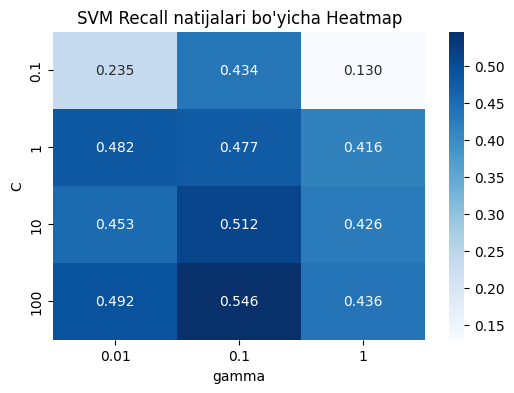

Eng yaxshi parametrlar: {'C': 100, 'gamma': 0.1}


In [121]:
from sklearn.model_selection import GridSearchCV
import seaborn as sns
import matplotlib.pyplot as plt

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.01, 0.1, 1]
}

grid = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='recall')
grid.fit(X_train, y_train)

# Natijalarni heatmap jadval ko'rinishiga keltirish
score_matrix = grid.cv_results_['mean_test_score'].reshape(len(param_grid['C']), len(param_grid['gamma']))

plt.figure(figsize=(6, 4))
sns.heatmap(score_matrix, annot=True, fmt='.3f', cmap='Blues',
            xticklabels=param_grid['gamma'], yticklabels=param_grid['C'])

plt.xlabel('gamma')
plt.ylabel('C')
plt.title('SVM Recall natijalari bo\'yicha Heatmap')
plt.show()

print(f"Eng yaxshi parametrlar: {grid.best_params_}")

In [123]:
# Oddiy model
svm_default = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_default.fit(X_train, y_train)
pred_def = svm_default.predict(X_test)

# Balanslangan model
svm_balanced = SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced', random_state=42)
svm_balanced.fit(X_train, y_train)
pred_bal = svm_balanced.predict(X_test)

balance_comparison = pd.DataFrame([
    {
        "Variant": "Standart SVM",
        "Accuracy": round(accuracy_score(y_test, pred_def) * 100, 2),
        "Precision": round(precision_score(y_test, pred_def) * 100, 2),
        "Recall": round(recall_score(y_test, pred_def) * 100, 2),
        "F1": round(f1_score(y_test, pred_def) * 100, 2)
    },
    {
        "Variant": "Balanced SVM",
        "Accuracy": round(accuracy_score(y_test, pred_bal) * 100, 2),
        "Precision": round(precision_score(y_test, pred_bal) * 100, 2),
        "Recall": round(recall_score(y_test, pred_bal) * 100, 2),
        "F1": round(f1_score(y_test, pred_bal) * 100, 2)
    }
])

print(balance_comparison)

        Variant  Accuracy  Precision  Recall     F1
0  Standart SVM     79.10      64.29   48.13  55.05
1  Balanced SVM     72.85      49.32   77.81  60.37
